#### This file is for testing the model on a single test F=8

In [1]:
import pandas as pd
from run_experiment import run_experiment
import torch
from aiexperiments.config import load_config_from_files, SubExperimentConfig
from aiexperiments.constants import EventOrderingMethod, network_extensions_from_string
from aiexperiments.visualizing.plotting.spike_order.per_sample import (
    plot_event_order_recordings_from_tensor,
    plot_membrane_potentials
)
import aiexperiments.visualizing.plotting.spike_order.per_sample as per_sample
import importlib
from aiexperiments.visualizing.results import SingleExperimentOutputKey
import numpy as np
from aiexperiments.constants import EventSchedulingMethod
import matplotlib.pyplot as plt
device = torch.device("cpu") # torch.device("cuda" if torch.cuda.is_available() else "cpu")

c:\Users\shago\anaconda3\envs\asyncinf-np1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import numpy as np, h5py # Roels code seems to be using numpy1
print(np.__version__)
with h5py.File("./data/SHD/shd_test.h5", "r") as f:
    t = f["spikes/times"][0]
    print(t.dtype, t.max(), (t * 1e6).dtype, (t * 1e6).max())

1.26.4
float16 0.7305 float32 730468.75


In [ ]:
# the Readme file runs experiments from the command prompt line, but there it runs three subexperiments (inference on F=1, F=8 and F=128, as the paper also do layered inference)

limit_n_samples = 2264
series_id = "shd"
experiment_id = 30
# overall, dropout is very helpful for async, and can also help sync
# a bit of positive skew seems to help in sync and keep async performance
# too positive skew seems to further help in sync, but make async worse
# negative seems to just deteriorate performance overall
# accumulate early seems to also just deteriorate performance overall
inference_dt = 10000
sync_barrier = EventOrderingMethod.NONE
network_extensions = 'async_torch/8/membrane_potential,log_spike_dynamics,stop_on_output/1'# barrier_lif/1,input_barrier' #async_torch/8/random' #
sub_experiment_config = SubExperimentConfig(
    inference_dt,
    batch_size=128,
    sync_barrier=sync_barrier,
    network_extensions=network_extensions_from_string(network_extensions),
    limit_n_samples=limit_n_samples,
    shuffle_samples=False,
    event_scheduling_method=EventSchedulingMethod.RANDOM_SAMPLING
)
#neurons_per_layer = np.array([6, 6, 6, 2]) # TODO: get this from the model
#neurons_per_layer = np.array([64, 64, 64, 10])
neurons_per_layer = np.array([128, 128, 128, 20])
#n_inputs = 9
#n_inputs = 34 * 34 * 2
n_inputs = 128

# Load experiment
experiments_file = f"./experiments/{series_id}.xlsx"
df_experiments = pd.read_excel(experiments_file, index_col=0)
experiment_row = df_experiments.loc[experiment_id]
print(experiment_row)
model_id = experiment_row["model id"]
config_name = experiment_row["config"]
df_models = pd.read_excel(f"./models/model_descriptions_{series_id}.xlsx", index_col=0)
model_row = df_models.loc[model_id]
shared_experiment_configs = load_config_from_files(
    f"./experiments/shared_config.json", f"./experiments/experiment_config_{config_name}.json", model_timestep_size=int(model_row["timestep size"])
)
shared_experiment_config = shared_experiment_configs.shared_experiment_configs[
    model_row["data"]
][experiment_row["inference method"]]
shared_experiment_config.sub_experiments = [
    sub_experiment_config
]  # overwrite the default sub-experiment
shared_experiment_config.track_order_recordings = (limit_n_samples == 1)
shared_experiment_config.track_membrane_recordings = (limit_n_samples == 1)

# Run experiment
output = run_experiment(
    experiment_row, shared_experiment_config, model_row, series_id, device
)
output_key = SingleExperimentOutputKey(
    inference_dt,
    sub_experiment_config.sync_barrier.name.lower(),
    network_extensions
)
print("Accuracy:", output.accuracy)
print("Loss:", output.loss)
#output.labels

model id                   3
inference method      matrix
config              final_MS
Name: 3, dtype: object
MLP network structure: [128, 128, 128, 20]
Testing timestep size 10000 and batch size 128
Loading test data...
Fixing sample length to 100 steps, each step 10000 microseconds
Initializing network...
Testing...
Limiting number of samples to 2264


100%|██████████| 17/17 [01:28<00:00,  5.23s/it]


Accuracy: 0.8140459363957597
Loss: 2.6389695570241436


Latency: 35.38586904875036
Spike count: 2390.4084


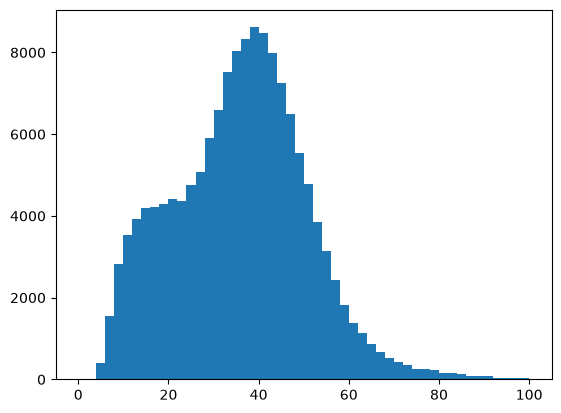

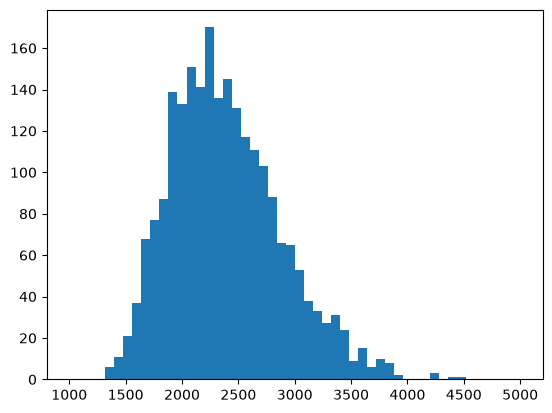

In [4]:
print('Latency:', output.classification_latencies[output_key].mean())
print('Spike count:', output.spike_counts[output_key].sum(axis=1).mean())

plt.hist(output.classification_latencies[output_key], bins=50, range=(0,100))
plt.show()
plt.hist(output.spike_counts[output_key].sum(axis=1), bins=50, range=(1000,5000))
plt.show()

In [5]:
plot_membrane_potentials(
    output.membrane_recordings[output_key][0][:,:].squeeze(),
    output.membrane_timesteps[output_key][0][:],
    neurons_per_layer,
    title="Evolving membrane potentials per spike",
    figsize=(12, 5),
    #xlim=(690,740)
)

KeyError: SingleExperimentOutputKey(inference_dt=10000, sync_barrier='none', inference_nn_extensions='async_torch/8/membrane_potential,log_spike_dynamics,stop_on_output/1')

In [11]:
importlib.reload(per_sample)
from aiexperiments.utils import load_weights_from_file
#weights = load_weights_from_file('./models/nmnist/9.pt', device)
if output_key in output.order_recordings:
    per_sample.plot_event_order_recordings_from_tensor(
        output.order_recordings[output_key][:, 0, :], # [timestep, sample, neuron]
        list(neurons_per_layer),
        n_inputs=n_inputs,
        timestep_size=inference_dt,
        show_inputs=False,
        show_output=series_id == "nmnist",
        title="Spikes in network in bins of 10 ms each",
        #weights=weights,
        figsize=(11, 11),
    )